# 3. Transfer Learning with MobileNetV2

## 3.1 Objective

In this section, we develop an image classification model using transfer learning to classify waste images into six categories:

- Cardboard
- Glass
- Metal
- Paper
- Plastic
- Trash

We use MobileNetV2, a pre-trained convolutional neural network originally trained on the ImageNet dataset.

Instead of training a deep neural network entirely from scratch, transfer learning allows us to reuse previously learned image features and adapt the model to our waste classification task.

### Why Transfer Learning?

Training a deep learning model from scratch can require a large dataset and significant computational resources. Transfer learning provides a practical alternative by using knowledge learned from a large image dataset.

### Project Approach

1. Load the shared TrashNet dataset and use the same train, validation and test split as the other models.
2. Prepare images for MobileNetV2.
3. Load the pre-trained MobileNetV2 model.
4. Adapt the model for six waste categories.
5. Train and monitor the model using the training and validation datasets.
6. Evaluate its performance using appropriate classification metrics.

**Important:** The test dataset will be kept separate from model training and validation. We will use it for final evaluation and comparison with the other models.

## 3.2 Dataset and Shared Data Split

To ensure a fair comparison between all models in our project, we use a common dataset split defined in the shared project utilities.

The dataset contains 2,524 unique images across six waste categories.

The images are divided into three subsets:

- Training: 1,764 images (70%)
- Validation: 378 images (15%)
- Testing: 382 images (15%)

The split is created using a fixed random seed to support reproducibility and consistent model evaluation.

We use the same image assignments for all models rather than creating a new random split for each approach.

### Data handling

- **Training set:** Used to train the model and update its parameters.
- **Validation set:** Used to monitor model performance during training and guide model selection.
- **Test set:** Kept separate and used only for final model evaluation.

Using a shared split ensures that model comparisons are fair and consistent.

## 3.3 Setup and Imports


In [1]:
# Standard libraries
import sys
import random
from pathlib import Path
import seaborn as sns

# Data processing
import pandas as pd
import numpy as np
from PIL import Image


# Data Visualization
import matplotlib.pyplot as plt

# Pytorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Torchvision
from torchvision import models, transforms
from torchvision.models import MobileNet_V2_Weights

# Model evaluation
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix, classification_report, roc_auc_score)

# Project utilities
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT))
from src.data_utils import CLASSES, split_dataset

print("Project root:", ROOT)
print("Source folder exists:", (ROOT / "src").exists())

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Classes:", CLASSES)
print("PyTorch version:", torch.__version__)


Project root: c:\Users\Ghulam Murtaza\Desktop\Business Intelligence\Maskininlärning\trashnet-ml-project
Source folder exists: True
Device: cpu
Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
PyTorch version: 2.15.0+cpu


### 3.4 Image Preprocessing

MobileNetV2 expects images to have a consistent input size and format. Therefore, all images must be resized and converted into tensors before they can be passed to the model.

We also apply the preprocessing function associated with the pretrained MobileNetV2 weights. This ensures that the input images are prepared in the format expected by the pretrained model.

In [2]:
# Image preprocessing for MobileNetV2

weights = MobileNet_V2_Weights.DEFAULT

preprocess = weights.transforms()

print("Image preprocessing ready.")
print("Input Size:", weights.transforms().crop_size)

Image preprocessing ready.
Input Size: [224]


### 3.5 Creating a Custom Dataset

To work with image data in PyTorch, we create a custom Dataset class. This class allows us to load images, apply preprocessing transformations, and retrieve the corresponding labels.

The dataset will use the previously defined training, validation, and testing splits to ensure that the same data partitioning is maintained across all models in the project.

In [3]:

class TrashDataset(Dataset):
    def __init__(self, files, classes, transforms=None):
        self.files = files
        self.classes = classes
        self.transform = transforms

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        image_path, label = self.files[idx]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = self.classes.index(label)    

        return image, label

        



### 3.6 Preparing Training, Validation and Test Datasets

We create separate PyTorch Dataset objects for the training, validation and test sets.

The same shared data split is used to ensure that the models in our project are trained and evaluated on consistent image sets.

MobileNetV2 preprocessing is applied to each image when it is loaded.

In [4]:
train_files, val_files, test_files = split_dataset(seed=42)

# Create Pytorch Datasets

train_dataset = TrashDataset(train_files, CLASSES, transforms=preprocess)
val_dataset = TrashDataset(val_files, CLASSES, transforms=preprocess)
test_dataset = TrashDataset(test_files, CLASSES, transforms=preprocess)

print("Training Dataset:", len(train_dataset))
print("Validation Dataset:", len(val_dataset))
print("Testing Dataset:", len(test_dataset))

Training Dataset: 1764
Validation Dataset: 378
Testing Dataset: 382


### 3.7 Creating DataLoaders

DataLoaders are used to load images in batches during model training and evaluation.

Instead of processing all images at once, the training DataLoader divides the dataset into smaller batches. This makes training more manageable and allows the model to update its parameters batch by batch.

We use separate DataLoaders for training, validation and testing. The training data is shuffled to improve learning, while validation and test data remain in a fixed order for consistent evaluation.

In [5]:
# Create Dataloaders

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

Training Batches: 56
Validation Batches: 12
Testing Batches: 12


### 3.8 Loading the Pre-trained MobileNetV2 Model

We use MobileNetV2 with pre-trained ImageNet weights. The model has already learned to recognize many visual features, such as edges, shapes, textures and patterns.

Instead of training the entire network from scratch, we reuse these learned features and adapt the model to classify waste images into our six categories.

In [6]:
# Load the pre-trained MobileNetV2 model

model = models.mobilenet_v2(weights=weights)

print("ModelNetV2 model loaded successfully.")

ModelNetV2 model loaded successfully.


### 3.9 Adapting MobileNetV2 for Waste Classification

The pre-trained MobileNetV2 model was originally designed to classify images into 1,000 ImageNet categories. Our waste classification task contains only six categories.

We therefore replace the original classification layer with a new fully connected layer containing six output neurons, one for each waste category. This allows the model to produce predictions for our specific classification task.

In [7]:
# Replace the original classification layer

model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    len(CLASSES)
)

print("Number of output classes:", len(CLASSES))
print(model.classifier)

Number of output classes: 6
Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=6, bias=True)
)


**Interpretation**

The original MobileNetV2 classification layer has been successfully replaced with a new fully connected layer containing six output neurons. The layer receives 1,280 input features and produces six outputs corresponding to our waste categories.

This confirms that the pre-trained model has been adapted to our six-class waste classification task. The original feature extraction architecture is retained, while the final classification layer is customized for our dataset.

### 3.10 Freezing the Pre-trained Layers

We freeze the pre-trained MobileNetV2 feature extraction layers to preserve the knowledge learned from ImageNet. This prevents their weights from being updated during the initial training phase.

Only the newly added classification layer will be trained. This allows the model to adapt to our six waste categories while retaining the previously learned image features.

In [8]:
# Freeze the pre-trained layers

for param in model.features.parameters():
    param.requires_grad = False

# Keep the new classification layer trainable

for param in model.classifier.parameters():
    param.requires_grad = True

print("1)Pre-trained layers frozen.")
print("2)Classifier remains trainable.")    



1)Pre-trained layers frozen.
2)Classifier remains trainable.


### 3.11 Verifying Trainable Parameters

After freezing the pre-trained feature extraction layers, we verify which parameters remain trainable.

This check helps confirm that the model is configured correctly before training. Only the parameters of the newly added classification layer should be updated during the initial training phase.

In [9]:
# Check trainable and total parameters

trainable_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

total_params = sum(
    p.numel() for p in model. parameters()
)

print("Trainable Parameters:", trainable_params)
print("Total Parameters:", total_params)
print("Percentage Trainable:", round(trainable_params/total_params*100, 2), "%")

Trainable Parameters: 7686
Total Parameters: 2231558
Percentage Trainable: 0.34 %


### Interpretation

Only 0.34% of the model's parameters are trainable, while the remaining parameters are frozen. This means that we reuse the features learned by MobileNetV2 during its original training and only train the new classification layer for our six waste categories.

This reduces the computational requirements and makes transfer learning more efficient than training the entire network from scratch.

### 3.12 Defining the Loss Function and Optimizer

We define a loss function to measure the difference between the model's predictions and the actual labels. The optimizer is responsible for updating the trainable model parameters to reduce this error during training.

Since this is a multi-class classification problem with six waste categories, we use Cross-Entropy Loss. We use Adam as the optimizer to update the trainable parameters of the model.

In [10]:
# Define loss function and optimizer

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

print("Loss Function:", criterion)
print("Optimizer:", optimizer)

Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


### 3.13 Training Function

We define a function to train the model for one epoch. During training, the model processes batches of images, generates predictions, calculates the loss, and updates the trainable parameters through backpropagation and the optimizer.

We also track the average training loss and accuracy to monitor the model's learning progress.

In [11]:
# Function to train the model for one epoch

def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy 

### 3.14 Validation Function

We define a validation function to evaluate the model on the validation dataset after each training epoch.

Unlike training, validation does not update model weights. It measures the model's performance on data that is not used for weight updates, allowing us to monitor its learning progress and detect potential overfitting.

In [12]:
# Function to validate the model

def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    average_loss = total_loss / total
    accuracy = correct / total

    return average_loss, accuracy


### 3.15 Training Loop

We train the MobileNetV2 model over multiple epochs. During each epoch, the model learns from the training dataset and is evaluated on the validation dataset.

We track training and validation loss and accuracy to monitor the learning process and identify potential overfitting.


In [13]:
# Select device (GPU if available, otherwise CPU)

model = model.to(device)

print("Using device:", device)

Using device: cpu


In [14]:
# Number of epochs

NUM_EPOCHS = 5

# Store training history
history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

# Training loop
for epochs in range(NUM_EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy = validate_one_epoch(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    print(f"Epoch[{epochs+1}/{NUM_EPOCHS}]")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy:{train_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f} | Validation Accuracy: {val_accuracy:.4f}")
    print("-" * 50)

Epoch[1/5]
Train Loss: 1.2953 | Train Accuracy:0.5703
Validation Loss: 0.9684 | Validation Accuracy: 0.7011
--------------------------------------------------
Epoch[2/5]
Train Loss: 0.8491 | Train Accuracy:0.7540
Validation Loss: 0.7919 | Validation Accuracy: 0.7540
--------------------------------------------------
Epoch[3/5]
Train Loss: 0.7103 | Train Accuracy:0.7755
Validation Loss: 0.7128 | Validation Accuracy: 0.7751
--------------------------------------------------
Epoch[4/5]
Train Loss: 0.6092 | Train Accuracy:0.8169
Validation Loss: 0.6650 | Validation Accuracy: 0.8095
--------------------------------------------------
Epoch[5/5]
Train Loss: 0.5597 | Train Accuracy:0.8362
Validation Loss: 0.6331 | Validation Accuracy: 0.7963
--------------------------------------------------


### Training Results Interpretation

The model's training loss decreased from 1.2953 to 0.5597 over five epochs, while training accuracy increased from 57.03% to 83.62%. This indicates that the model progressively learned to classify the training images.

Validation loss decreased from 0.9684 to 0.6331, and validation accuracy improved from 70.11% to 79.63%. This suggests that the model also improved its performance on unseen validation data during training.

The training and validation results show a similar improvement trend. Although training accuracy is slightly higher than validation accuracy at the end, there is no strong indication of severe overfitting after five epochs.

### 3.16 Training and Validation Loss

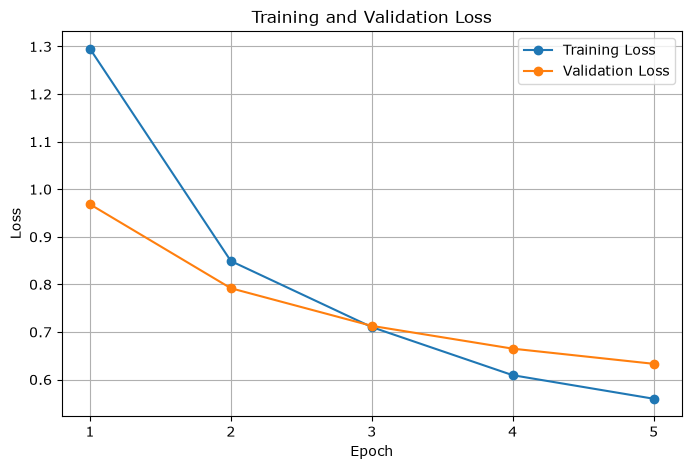

In [15]:
epochs = range(1, NUM_EPOCHS +1)

plt.figure(figsize=(8,5))

plt.plot(epochs, history["train_loss"], marker = "o", label="Training Loss")
plt.plot(epochs, history["val_loss"], marker = "o", label="Validation Loss")

plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(True)


plt.show()

### Interpretation

Training loss decreased steadily from 1.2953 to 0.5597 over the five epochs, indicating that the model progressively improved its predictions on the training data.

Validation loss also decreased from 0.9684 to 0.6331, showing an overall improvement in performance on unseen validation data.

Both curves follow a similar downward trend, suggesting that the model is learning without clear signs of severe overfitting. Although validation loss decreased throughout the training process, the validation accuracy showed a slight decrease during the final epoch, indicating that further training should be monitored carefully.

### 3.17 Training and Validation Accuracy

We visualize training and validation accuracy across the five epochs to observe how the model's classification performance improves during training and how well it performs on unseen data.

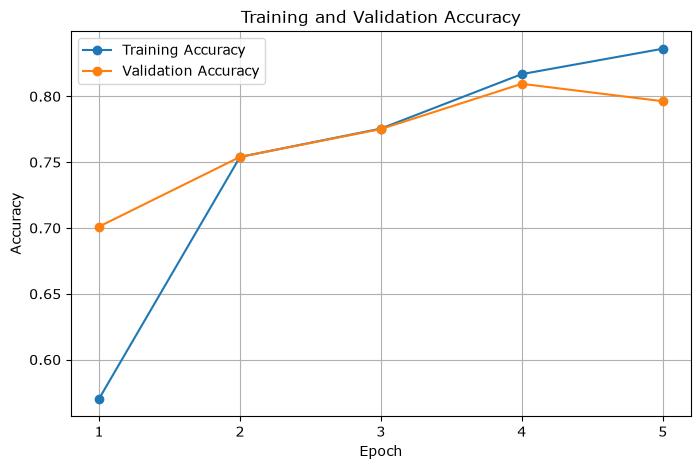

In [16]:

plt.figure(figsize=(8, 5))

plt.plot(epochs, history["train_accuracy"], marker="o", label="Training Accuracy")
plt.plot(epochs, history["val_accuracy"], marker="o", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.show()


### Interpretation

The accuracy curves show an overall upward trend for both training and validation accuracy, indicating that the model's classification performance improved during training. Training accuracy increased from 57.03% to 83.62%, while validation accuracy improved from 70.11% to 79.63%.

Training accuracy remained slightly higher than validation accuracy towards the end of training, which is expected. Validation accuracy decreased slightly during the final epoch, suggesting that the model's performance on unseen validation data did not continue to improve. However, the overall trend indicates that the model learned useful features and generalized reasonably well to unseen images.

### 3.18 Evaluation on the Test Dataset

In [17]:
# Collect predictions from the test dataset

def get_predictions(model, loader, device):
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            predictions = torch.argmax(outputs, dim=1)

            y_true.extend(labels.numpy())
            y_pred.extend(predictions.cpu().numpy())

    return y_true,y_pred


# Generate predictions test dataset
y_true, y_pred = get_predictions(model, test_loader,device) 


# Check total predictions
print("Number of test samples:", len(y_true))
print("Number of predictions:", len(y_pred))
print(classification_report(y_true, y_pred, target_names=CLASSES))

Number of test samples: 382
Number of predictions: 382
              precision    recall  f1-score   support

   cardboard       0.82      0.82      0.82        61
       glass       0.86      0.67      0.76        76
       metal       0.71      0.95      0.81        62
       paper       0.81      0.88      0.84        90
     plastic       0.86      0.78      0.82        72
       trash       0.81      0.62      0.70        21

    accuracy                           0.81       382
   macro avg       0.81      0.79      0.79       382
weighted avg       0.82      0.81      0.80       382



### Interpretation

The model was evaluated on 382 images from the test dataset, and it generated 382 predictions. This confirms that every test image received a prediction and that the number of actual labels matches the number of predicted labels.

The model achieves an overall accuracy of 81%, indicating that it correctly classifies most of the images in the test dataset. The results vary between classes, with paper showing the highest F1-score and trash the lowest. Metal has a high recall but lower precision, meaning that the model identifies most metal images but also incorrectly classifies some images from other classes as metal. Glass and trash have lower recall, indicating that the model misses a number of images belonging to these categories.

The macro average F1-score is 0.79, showing the model's average performance across all six classes while giving each class equal importance. The weighted average F1-score is 0.80, taking the number of images in each class into account. Overall, the model demonstrates good classification performance, although some classes are more difficult to distinguish than others.

### Confusion Matrix

A confusion matrix is used to evaluate the model's classification performance by comparing the actual labels with the predicted labels. It shows how many images were correctly classified for each class and which classes the model confused with each other. This helps identify patterns in the model's errors and understand which categories are more difficult to distinguish.

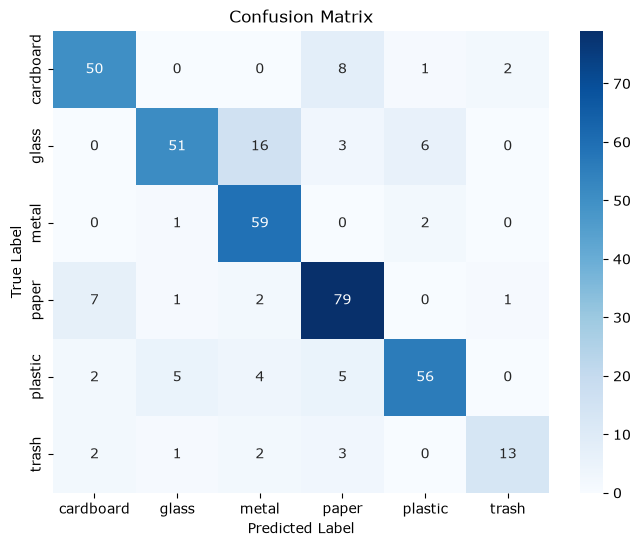

In [18]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

### Interpretation

The **confusion matrix** shows that the model correctly classifies images across all six waste categories, but its performance varies between classes. Paper has a strong classification result, with 79 images correctly classified, while cardboard has 50 correct predictions.

The most noticeable confusion occurs between glass and metal, where 16 glass images are incorrectly classified as metal. Plastic is also sometimes confused with glass, metal and paper. Trash remains a challenging category, with relatively few images correctly classified.

Overall, the confusion matrix provides a detailed view of the model's predictions and highlights which waste categories are more difficult to distinguish.

### Multiclass ROC-AUC Score

In [19]:
def get_probabilities(model, loader, device):
    model.eval()

    probabilities = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)

            probabilities.extend(probs.cpu().numpy())

    return np.array(probabilities)


y_prob = get_probabilities(model, test_loader, device)

print("Probability shape:", y_prob.shape)

Probability shape: (382, 6)


In [20]:
# Calculate multiclass ROC-AUC score
roc_auc = roc_auc_score(
    y_true,
    y_prob,
    multi_class="ovr",
    average="macro"
)

print("Multiclass ROC-AUC:", round(roc_auc, 3))

Multiclass ROC-AUC: 0.967


### Interpretation

The MobileNetV2 model achieved a macro ROC-AUC score of 0.967 on the test dataset. This indicates that the model has a strong ability to distinguish between the six waste categories based on the predicted probability scores. The high ROC-AUC score suggests that the model can separate the classes well, even when some images are incorrectly classified. This complements the accuracy and macro F1-score by evaluating the model's ability to distinguish between classes using probability scores.

### 3.19 Final Evaluation Summary

MobileNetV2 was used with transfer learning to classify waste images into six categories: cardboard, glass, metal, paper, plastic, and trash. The model was trained for five epochs using the training dataset and evaluated on the validation and test datasets.

The model achieved a **test accuracy of 81%**, a **Macro F1-score of 0.79**, and a **Macro ROC-AUC score of 0.967** on the test dataset containing 382 images.

The results show that the model can classify most waste images correctly. However, its performance varies between classes. Some categories, particularly glass and trash, are more challenging to classify than others. The classification report and confusion matrix provide further insight into these differences.

Overall, MobileNetV2 with transfer learning demonstrates promising performance for the six-class waste classification task.

### 3.20 Saving the Trained Model

After training and evaluating the MobileNetV2 model, we save the trained model parameters so that the model can be reused without retraining.

Saving the model allows us to use the trained model later for predictions and potential integration into our waste classification application.

In [21]:

# Save the trained model

model_path = ROOT / "models"
model_path.mkdir(exist_ok=True)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "classes": CLASSES,
    },
    model_path / "mobilenetv2_trashnet.pth"
)

print("Model saved successfully.")


Model saved successfully.


## 3.21 Model Comparison

In this project, we compare three machine learning approaches for waste image classification: a Colour Random Forest baseline, a CNN trained from scratch, and MobileNetV2 using transfer learning.

All models are evaluated using the same test dataset to ensure a fair comparison. We use accuracy, macro F1-score and weighted F1-score to compare their performance.

Accuracy measures the overall proportion of correctly classified images. Macro F1-score gives equal importance to all six classes, while weighted F1-score considers the number of images in each class.

The comparison helps us understand whether a more complex model provides better classification performance than simpler approaches.

| Model | Accuracy | Macro F1-score | Macro ROC-AUC |
|---|---:|---:|---:|
| Colour Random Forest | 0.790 | 0.803 | 0.964 |
| Baseline CNN | 0.767 | 0.746 | 0.955 |
| MobileNetV2 | 0.806 | 0.790 | 0.967 |

### Model Comparison Interpretation

The comparison shows that MobileNetV2 achieved the highest accuracy (0.806) and Macro ROC-AUC (0.967) among the three models. This indicates that it correctly classified the largest proportion of test images and demonstrated the strongest ability to distinguish between the six waste categories.

The Colour Random Forest achieved the highest Macro F1-score (0.803), slightly outperforming MobileNetV2 (0.790). This suggests that Colour Random Forest performed slightly better when considering the balance between precision and recall across all six classes.

The Baseline CNN achieved the lowest scores across all three metrics, with an accuracy of 0.767, Macro F1-score of 0.746, and Macro ROC-AUC of 0.955.

Overall, MobileNetV2 and Colour Random Forest performed better than the Baseline CNN, but the results show that no single model was best across every evaluation metric.

## 3.22 Limitations

Although MobileNetV2 achieved promising results, the model has some limitations.

- **Limited dataset:** The model was trained and evaluated on a relatively small dataset. Its performance may differ when applied to new waste images collected in real-world environments.
- **Class imbalance:** The Trash class contains fewer images than the other classes, which may contribute to its lower classification performance.
- **Class confusion:** The model sometimes confuses Glass with Metal, indicating that visually similar materials can be challenging to distinguish.
- **Frozen feature extractor:** The pretrained feature layers were frozen during training. Fine-tuning these layers may improve performance on the TrashNet dataset.
- **Real-world conditions:** The model has not yet been tested in real waste sorting environments with varying lighting conditions, backgrounds, object orientations, and image quality.

## 3.23 Future Improvements

Based on the evaluation results, several improvements could be explored in future experiments:

- **Expand the dataset:** Collect more images, particularly for the underrepresented Trash class, to improve classification performance.
- **Improve image diversity:** Include images with different lighting conditions, backgrounds, angles, and image quality.
- **Reduce class confusion:** Investigate methods to improve the distinction between Glass and Metal, as these classes were frequently confused.
- **Fine-tune the pretrained model:** Unfreeze selected MobileNetV2 layers and fine-tune them to adapt the model more closely to the TrashNet dataset.
- **Evaluate on real-world images:** Test the model on images from real waste sorting environments to assess how well it generalizes beyond the dataset.